# Project 1 – Pass-02



## Problem Definition



Business problem: Predict whether a customer will make a transaction,

Data Science problem: This is a supervised learning and classification problem. I will use the Gaussian Naive Bayes model





## Data Collection

### Imports

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn import datasets, metrics, model_selection

### File Paths

In [ ]:
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.1-Transactions/Data/Transaction.train.csv'

### Load data

In [ ]:
#load data
transaction_df= pd.read_csv(url)

### Head

In [ ]:
# first few rows
transaction_df.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
0,0,train_0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,...,5.4879,-4.7645,3.1531,18.5618,1.7202,25.8398,4.4354,3.9642,3.1364,12.7803
1,1,train_1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,...,5.7999,5.5378,5.5134,30.2645,11.0752,22.5441,7.6421,7.7214,2.5837,18.3560
2,2,train_2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,...,5.7690,-7.0927,-5.8234,25.6820,2.4013,23.0866,2.9057,9.7905,1.6704,14.7222
3,3,train_3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,...,5.3430,-7.1541,11.7134,14.7483,5.6961,-0.4639,4.4666,4.7433,0.7178,17.9697
4,4,train_4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,...,5.5518,1.4493,2.3705,18.4685,5.1743,11.8503,-1.4905,9.5214,-0.1508,17.9974


### Tail

In [ ]:
# last few rows
transaction_df.tail()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
179995,179995,train_179995,0,8.9112,-4.4900,11.3795,5.4164,8.3309,14.1869,12.8219,...,5.9355,5.1764,-5.4817,20.7390,-0.8043,31.3663,8.7194,4.7839,0.9673,14.9529
179996,179996,train_179996,0,8.2722,7.1923,16.7300,4.9698,5.4907,14.0238,11.9933,...,5.3550,-1.5556,7.3839,9.9193,5.0860,28.0185,7.4145,4.2814,2.5575,15.3969
179997,179997,train_179997,0,12.4902,-2.9379,6.5901,4.7242,9.1423,13.9133,12.2314,...,6.0708,-0.3463,-5.0098,20.4807,5.9814,20.2668,3.1006,3.7701,0.1299,16.1256
179998,179998,train_179998,0,8.4894,0.7048,11.1518,4.6370,8.1321,14.2921,6.9582,...,5.5161,3.1774,-4.9374,23.6365,1.0432,29.9365,9.6381,6.9649,2.5546,15.6760
179999,179999,train_179999,0,11.6252,3.3959,11.5558,4.2003,7.4666,13.7381,12.9590,...,5.0415,-2.4210,-3.6829,14.2422,1.0741,26.3943,4.1482,11.9539,2.9846,15.6002


### Shape

In [ ]:
# shape of data frame
transaction_df.shape

#output (# of rows, # of columns)

(180000, 53)

### Size

In [ ]:
# size of data frame
transaction_df.size

9540000

### Info

In [ ]:
# display meta-data
transaction_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180000 entries, 0 to 179999
Data columns (total 53 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Unnamed: 0  180000 non-null  int64  
 1   ID_code     180000 non-null  object 
 2   target      180000 non-null  int64  
 3   var_0       180000 non-null  float64
 4   var_1       180000 non-null  float64
 5   var_2       180000 non-null  float64
 6   var_3       180000 non-null  float64
 7   var_4       180000 non-null  float64
 8   var_5       180000 non-null  float64
 9   var_6       180000 non-null  float64
 10  var_7       180000 non-null  float64
 11  var_8       180000 non-null  float64
 12  var_9       180000 non-null  float64
 13  var_10      180000 non-null  float64
 14  var_11      180000 non-null  float64
 15  var_12      180000 non-null  float64
 16  var_13      180000 non-null  float64
 17  var_14      180000 non-null  float64
 18  var_15      180000 non-null  float64
 19  va

## Summary statistics

### Describe

In [ ]:
# display summary statistics
transaction_df.describe()


,Unnamed: 0,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
count,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.00000,180000.000000,...,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000
mean,89999.500000,0.100222,10.678650,-1.630045,10.712922,5.408688,7.566953,14.024017,8.52808,15.243424,...,5.635897,-0.000418,-0.668334,20.208845,2.595090,12.756574,3.236201,7.440715,1.927078,15.870166
std,51961.668564,0.300297,3.041036,4.050519,2.639146,0.866265,1.235043,0.190038,4.64170,7.851050,...,0.369629,4.422915,5.968300,7.132446,2.801692,9.320939,4.561317,3.021636,1.476777,3.010492
min,0.000000,0.000000,0.408400,-15.043400,2.117100,2.347300,3.970500,13.434600,-6.01110,-10.664200,...,4.258800,-14.506000,-22.748700,-2.995300,-7.856100,-18.489700,-14.093300,-2.691700,-3.814500,6.299300
25%,44999.750000,0.000000,8.451675,-4.745600,8.720000,4.768500,6.618800,13.893900,5.06575,9.170200,...,5.374200,-3.253575,-4.997500,15.062900,0.628600,5.661300,-0.062000,5.160325,0.890000,13.830400
50%,89999.500000,0.000000,10.526750,-1.611250,10.579600,5.385600,7.628500,14.025500,8.59920,15.198900,...,5.634500,0.008500,-0.560300,20.203300,2.513800,12.520300,3.204650,7.350950,1.899700,15.934600
75%,134999.250000,0.000000,12.756200,1.360225,12.514100,6.003200,8.583800,14.164400,12.27330,21.010500,...,5.905600,3.098325,3.632525,25.639125,4.396725,19.461725,6.409900,9.511125,2.947225,18.061425
max,179999.000000,1.000000,20.315000,10.376800,19.353000,8.447700,11.150600,14.654500,22.33150,41.748000,...,7.089000,16.731900,18.855400,43.546800,13.448700,44.363400,18.440900,16.716500,8.402400,26.079100


### Target value counts

NOTE: the ‘target’ column indicates a successful transaction (‘1’) or a no-transaction (‘0’). Verify these are the only values in that column, and that there are no nulls.

In [ ]:
# value_counts on target ; include nulls
transaction_df['target'].value_counts(dropna=False)

,count
target,
0,161960
1,18040


In [ ]:
#normalize value counts on target ; include nulls
transaction_df['target'].value_counts(normalize=True, dropna=False)

,proportion
target,
0,0.899778
1,0.100222


### Nulls

In [ ]:
# look for nulls
transaction_df.isnull().sum().sort_values(ascending=False)

#output null rows:none (every column has 0 nulls, so no row can contain one)

,0
Unnamed: 0,0
ID_code,0
target,0
var_0,0
var_1,0
var_2,0
var_3,0
var_4,0
var_5,0
var_6,0


### Column data types

In [ ]:
# display data types
transaction_df.dtypes.sort_values()

,0
Unnamed: 0,int64
target,int64
var_26,float64
var_27,float64
var_28,float64
var_29,float64
var_30,float64
var_31,float64
var_32,float64
var_33,float64


###Unique elements

In [ ]:
# number of unique elements in every column (works on the whole dataframe)
transaction_df.nunique().sort_values(ascending=False)

,0
Unnamed: 0,180000
ID_code,180000
var_35,137280
var_45,134537
var_13,131746
var_21,130573
var_8,130208
var_7,129702
var_17,129453
var_33,128142


In [ ]:
# actual unique values in one column
transaction_df['target'].unique()

array([0, 1])

## Data Cleaning



Backup #1

In [ ]:
# backup copy of the original data
transaction_df_backup= transaction_df.copy()


In [ ]:
# restore from backup
transaction_df=transaction_df_backup.copy()

### Keep only the target and features

Selected `target` for the target and `var_0 through var_19` for the features

In [ ]:
# select the target (first 1000 rows)
transaction_df_target=transaction_df[['target']].head(1000).copy()
transaction_df_target.shape

(1000, 1)

In [ ]:
# select the features
feature_cols =[] #start with an empty list to hold the features
for col in transaction_df.columns: #look at each column name
  if col.startswith ('var_'): #if the name start with 'var_, it's a feature
    feature_cols.append(col)
# check the list (show 50 names)
print(feature_cols)
print(len(feature_cols))

['var_0', 'var_1', 'var_2', 'var_3', 'var_4', 'var_5', 'var_6', 'var_7', 'var_8', 'var_9', 'var_10', 'var_11', 'var_12', 'var_13', 'var_14', 'var_15', 'var_16', 'var_17', 'var_18', 'var_19', 'var_20', 'var_21', 'var_22', 'var_23', 'var_24', 'var_25', 'var_26', 'var_27', 'var_28', 'var_29', 'var_30', 'var_31', 'var_32', 'var_33', 'var_34', 'var_35', 'var_36', 'var_37', 'var_38', 'var_39', 'var_40', 'var_41', 'var_42', 'var_43', 'var_44', 'var_45', 'var_46', 'var_47', 'var_48', 'var_49']
50


In [ ]:
# select the target and the features
feature_cols= feature_cols[0:20] #keep only the first 20 features (var_0 to var_19)

#keep only the first 1000 rows,(.head(# of rows))
transaction_df_target_feature = transaction_df[['target'] + feature_cols].head(1000).copy()

transaction_df_target_feature.shape #verify


(1000, 21)

## Recommendations for Data Cleaning

**1. Identifier Columns**
- **Two columns:** `Unnamed: 0` is row numbers and `ID_code` is customer ID. cannot help predict anything
- **Recommendation:** Drop both columns. (I kept only `target` and `var_0` to `var_4`.)

**2. Null values:** No feature column have nulls. no action needed

**3. Target nulls:** none, no rows dropped

**4. Feature columns with high null counts:** None

**5. Medium null counts:** none

**6. Low null counts:** none

**7. Null rows:** none


## Exploratory Data Analysis ##

### Normal distribution of features:histogram

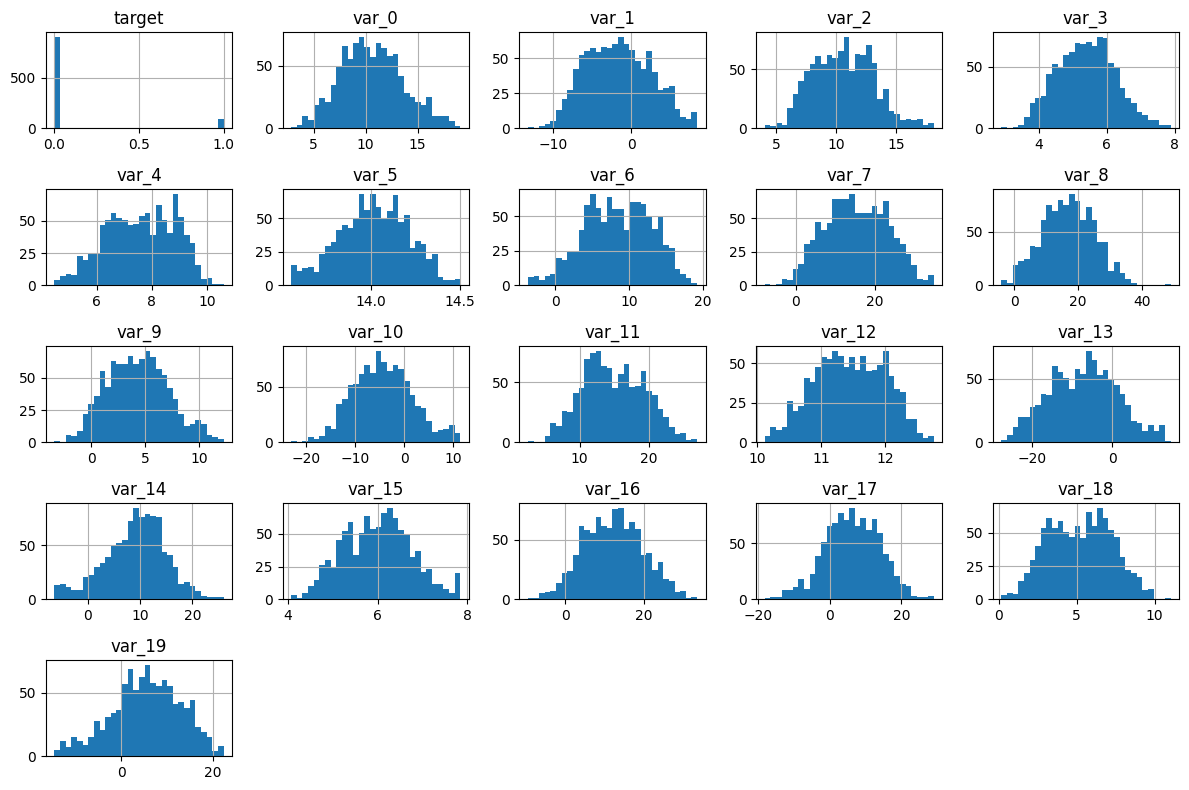

In [ ]:
# Display a histogram - overview of target and the 5 features

transaction_df_target_feature.hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()


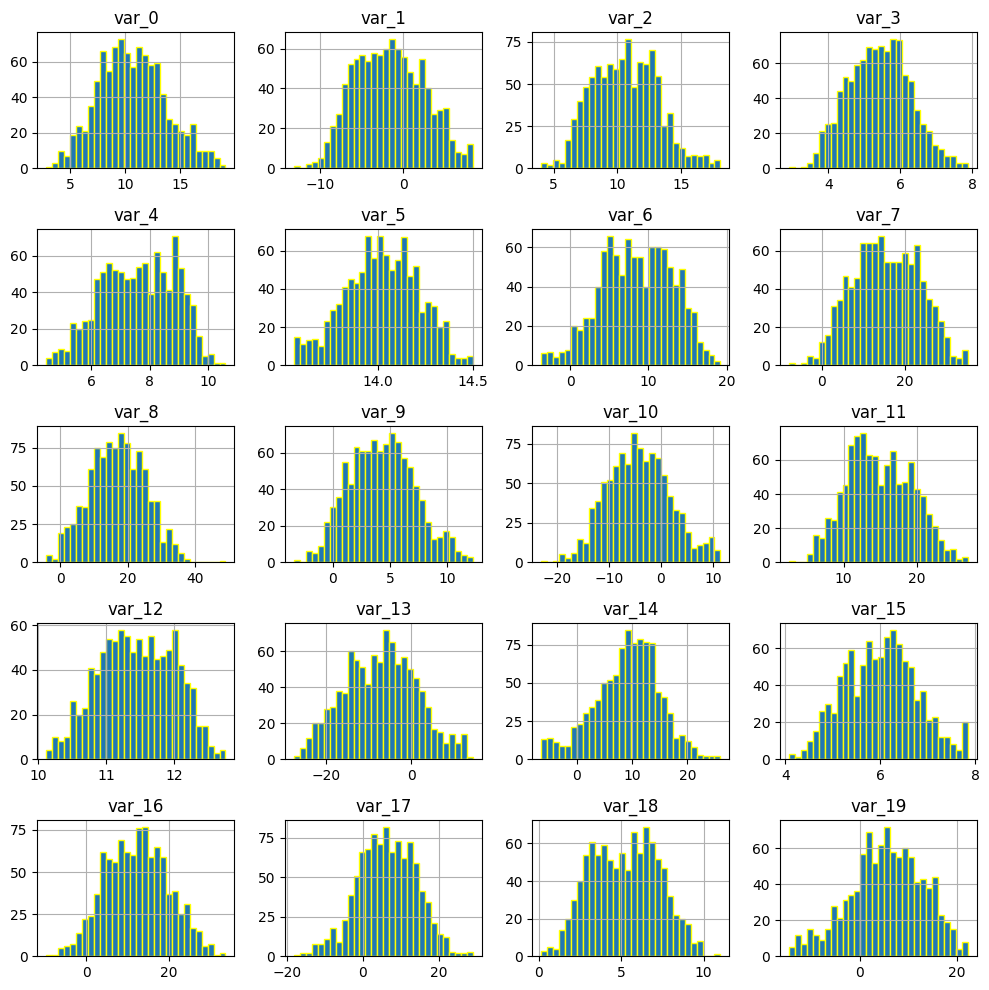

In [ ]:
# Check the distributions of the 20 features (var_0 to var_19)

transaction_df_target_feature[feature_cols].hist(
  figsize=(10,10), # size of the whole picture in inches(width,height)
  layout=(5,4),    # 5 rows, 4 column= 20 boxes
  bins=30,         # more bars, so the shape is clear
  edgecolor= "yellow"
)
plt.tight_layout()
plt.show()
#output- each graph look like a bell-shaped (first GNB assumption)

### Independence of features: Correlation matrix

In [ ]:
# Calculate a correlation matrix (target & features)
transaction_df_target_feature.corr()

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_10,var_11,var_12,var_13,var_14,var_15,var_16,var_17,var_18,var_19
target,1.000000,-0.017817,0.101429,0.025716,-0.011348,-0.005215,-0.088978,-0.034422,0.028374,-0.030690,...,0.024611,-0.088169,-0.034156,0.032045,-0.033832,0.009989,0.086618,-0.046206,0.000881,-0.051149
var_0,-0.017817,1.000000,0.016709,0.033530,-0.041718,-0.029472,0.031765,-0.031768,0.053884,-0.001246,...,0.012658,0.040331,-0.016348,0.001870,-0.045511,-0.030945,0.000387,-0.030731,0.015360,-0.011209
var_1,0.101429,0.016709,1.000000,0.054599,0.004523,-0.060222,0.029673,-0.009913,-0.013886,0.012571,...,-0.015433,0.036771,-0.006590,0.050830,-0.054055,-0.002712,0.056096,-0.061370,-0.033795,0.013637
var_2,0.025716,0.033530,0.054599,1.000000,-0.015892,0.007115,0.018316,-0.028780,-0.016959,-0.028103,...,0.010854,0.011465,0.000913,-0.013533,0.012850,-0.059216,0.029235,0.006385,-0.051744,-0.057251
var_3,-0.011348,-0.041718,0.004523,-0.015892,1.000000,-0.013690,0.005885,-0.001661,-0.018431,0.019194,...,-0.025975,-0.021268,-0.029692,0.022048,-0.026840,-0.017160,-0.028598,-0.014327,-0.025654,-0.010679
var_4,-0.005215,-0.029472,-0.060222,0.007115,-0.013690,1.000000,-0.054929,0.018787,-0.048617,-0.025843,...,-0.009370,-0.015352,-0.040256,-0.023076,-0.011870,0.019113,-0.051219,-0.031087,-0.027686,-0.052141
var_5,-0.088978,0.031765,0.029673,0.018316,0.005885,-0.054929,1.000000,-0.003199,0.009396,0.009989,...,-0.027920,0.003701,-0.023235,0.034798,0.013219,-0.037258,0.020763,0.011496,0.004586,-0.042694
var_6,-0.034422,-0.031768,-0.009913,-0.028780,-0.001661,0.018787,-0.003199,1.000000,-0.014602,-0.000257,...,0.013592,-0.058749,-0.053371,-0.022342,-0.008460,0.001974,-0.002136,-0.016087,-0.042815,0.025115
var_7,0.028374,0.053884,-0.013886,-0.016959,-0.018431,-0.048617,0.009396,-0.014602,1.000000,-0.067479,...,0.025885,0.031629,-0.004120,0.009993,0.014491,0.011159,0.015657,-0.005908,0.052932,-0.009540
var_8,-0.030690,-0.001246,0.012571,-0.028103,0.019194,-0.025843,0.009989,-0.000257,-0.067479,1.000000,...,0.005545,-0.013643,-0.013057,0.060894,0.043611,-0.047564,-0.016875,0.029409,0.010810,0.037673


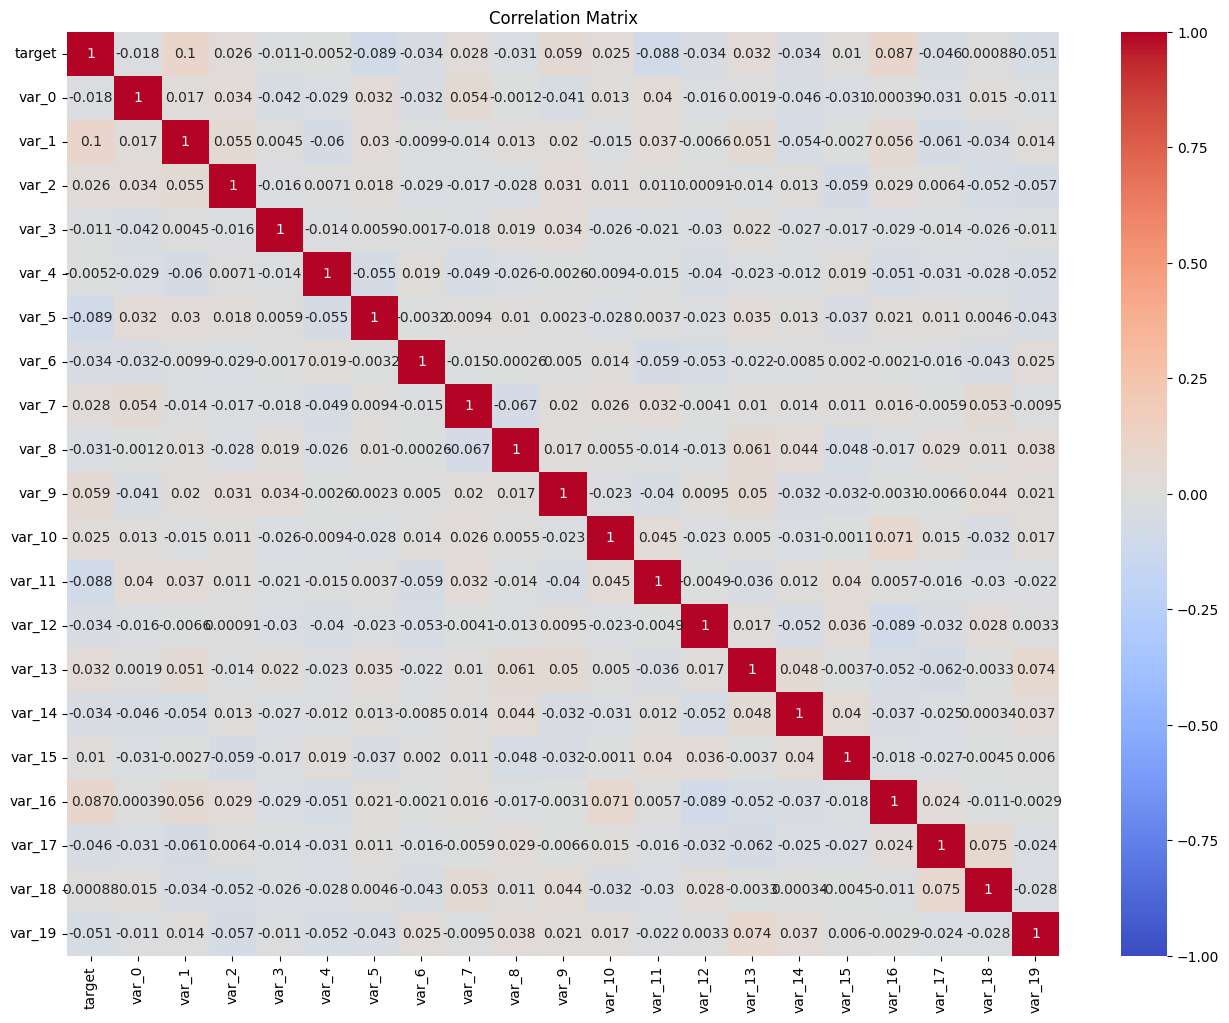

In [ ]:
# Display the correlation matrix

plt.figure(figsize=(16, 12))
sns.heatmap(transaction_df_target_feature.corr(),
            annot=True,
            cmap='coolwarm',  # blue = negative, red = positive
            center=0,         # white = no correlation
            vmin=-1, vmax=1)  # full correlation range
plt.title('Correlation Matrix')
plt.show()


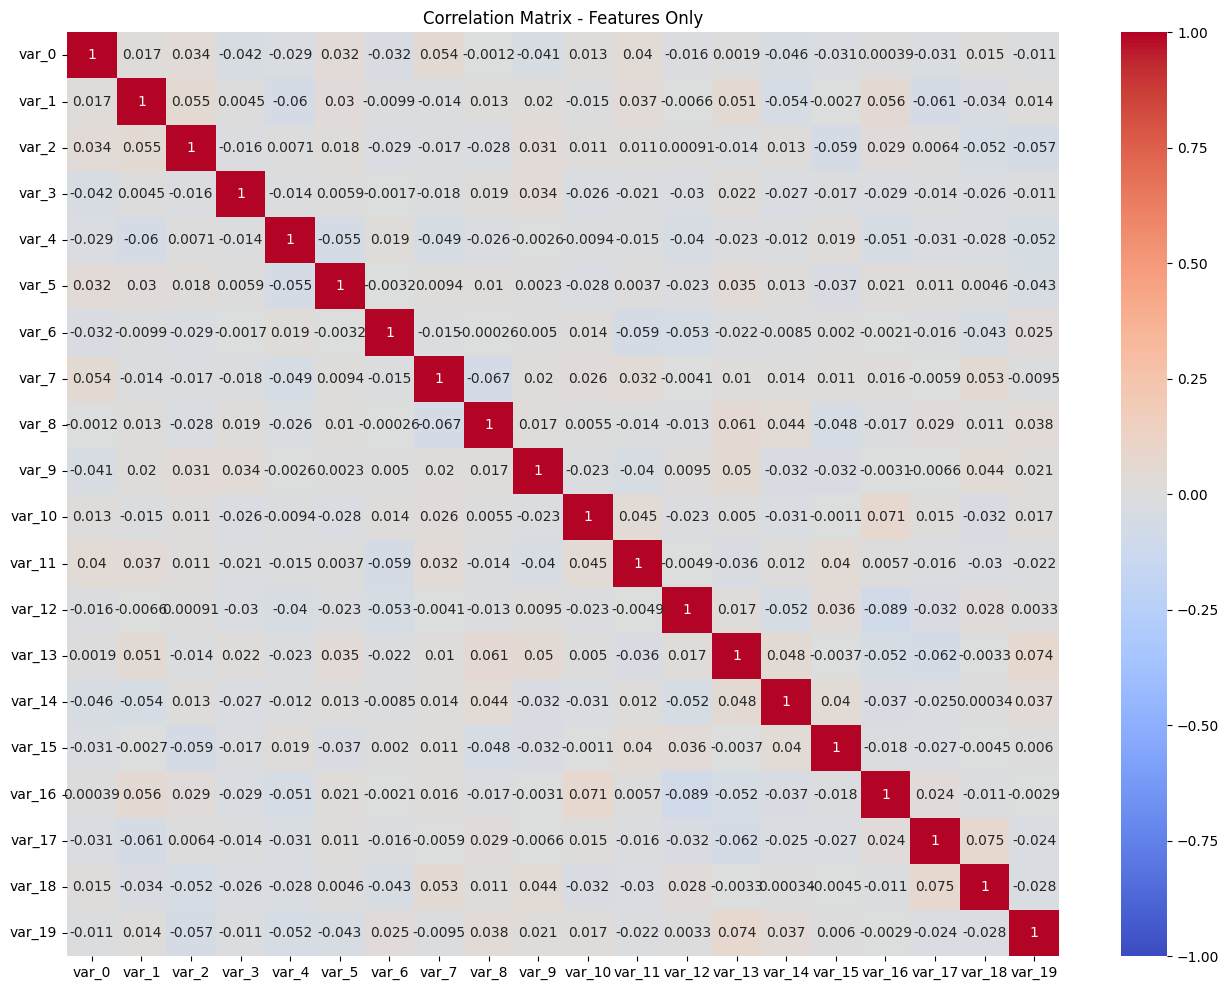

In [ ]:
# Calculate a correlation matrix (features only)
transaction_df_features_only = transaction_df_target_feature[feature_cols]
feature_corr = transaction_df_features_only.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(feature_corr,
            annot=True,
            cmap='coolwarm',  # blue = negative, red = positive
            center=0,         # white/gray = no correlation
            vmin=-1, vmax=1)  # full correlation range
plt.title('Correlation Matrix - Features Only')
plt.show()

#output- correlation between features are near 0
#look independent, 2nd GNB assumption


In [ ]:
# Create two data frames

# no transaction (target= 0)
transaction_df_no_success= transaction_df_target_feature[transaction_df_target_feature['target'] == 0].copy()

# successful transaction (target= 1)
transaction_df_successful= transaction_df_target_feature[transaction_df_target_feature['target'] == 1].copy()


print(type(transaction_df_successful))
print(type(transaction_df_no_success))

print(transaction_df_successful.shape)
print(transaction_df_no_success.shape)


<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.frame.DataFrame'>
(97, 21)
(903, 21)


## Data Processing

### Single Cross-validation

In [ ]:
# Split data from into target and features
target =transaction_df_target['target'].copy()
features= transaction_df_target_feature [feature_cols].copy()



In [ ]:
# Train test split
x_train, x_test, y_train, y_test = train_test_split( features, target, test_size=0.25, random_state=42)

In [ ]:
# verify shape of each data set from Train test split
for i in (x_train, x_test,y_train,y_test):
  print(i.shape)
  print(type(i))

(750, 20)
<class 'pandas.core.frame.DataFrame'>
(250, 20)
<class 'pandas.core.frame.DataFrame'>
(750,)
<class 'pandas.core.series.Series'>
(250,)
<class 'pandas.core.series.Series'>


### Model

In [ ]:
# Create an empty GNB model
modelGNB= GaussianNB()

### Fit

In [ ]:
# Train ( fit ) the model
modelGNB.fit(x_train,y_train)

GaussianNB()

### Prediction

In [ ]:
# Make prediction using the model
pred_result= modelGNB.predict(x_test)

### Performance

In [ ]:
# Calculate the accuracy
accuracy=metrics.accuracy_score(y_test,pred_result)
accuracy*100

90.0

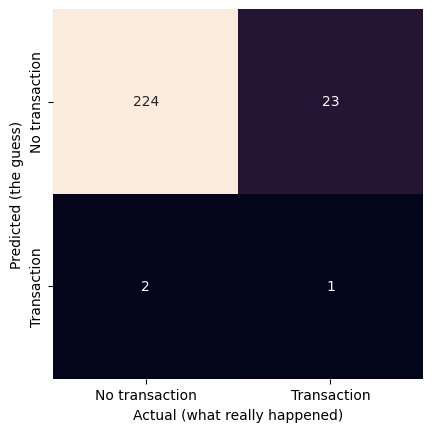

In [ ]:
# Display a confusion matrix
mat = metrics.confusion_matrix(y_test,pred_result)
names = ['No transaction', 'Transaction']
sns.heatmap(mat.T,
    square=True,
    annot=True,
    fmt='d',
    cbar=False,
    xticklabels=names,  #names start left to right
    yticklabels=names,  #names start from top to bottom
)

plt.xlabel('Actual (what really happened)')
plt.ylabel('Predicted (the guess)') ;

In [ ]:
#Classification report
print(metrics.classification_report(y_test, pred_result,zero_division=0 ))

#output show a warning message because model did not guess successful transactio
# zero_division=0 to remove the warning message


              precision    recall  f1-score   support

           0       0.91      0.99      0.95       226
           1       0.33      0.04      0.07        24

    accuracy                           0.90       250
   macro avg       0.62      0.52      0.51       250
weighted avg       0.85      0.90      0.86       250



### Communication of Results

The target show no transaction (‘0’) or  successful transaction (‘1’).

**Accuracy:** 90%


**Confusion matrix:**

 - 224: guessed no transaction, actually no transaction → right
  
 - 23: guessed no transaction, actually successfull transaction → wrong

 - 2: guessed sucessful transaction, actually no transaction -> wrong

 - 1: guess sucessful transaction, actually transaction ->right
  
**Classification report:**
  
  - Recall for successfull transaction: 0.04
    - The model found 1 out 24 successfull transaction.

  - Precision for successfull transaction: 0.33
    - The model said successfull transaction 3 times, right once  

  - 90% is just for the no transaction customer.

**Takeaway:** The model guessed "no transaction" for most customer transaction.

